.. index:: Grid construction; Filtered grid views

# FilteredGridView examples

In this example we use `filteredGridView` to filter out parts of a given
grid view.

In [1]:

from ufl import SpatialCoordinate, dot
from dune.grid import cartesianDomain
from dune.alugrid import aluConformGrid as leafGridView
from dune.fem.view import filteredGridView
from dune.fem.space import lagrange

Create a host grid view of the underlying grid as usual.

In [2]:

gridView = leafGridView( cartesianDomain([-1,0],[1,1],[50,25]) )

Now create a `filteredGridView` with a simple callable specifying which element belongs to the new domain.

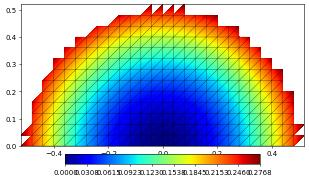

number of dofs: 5151 integral over filtered domain 0.048586239999999954


In [3]:
filterIds = lambda e: 10 if e.geometry.center.two_norm < 0.5 else 20
filteredView = filteredGridView(gridView, filterIds, domainId=10)
space = lagrange(filteredView, order=2)
x = SpatialCoordinate(space)
solution = space.interpolate(dot(x,x),name="solution")
solution.plot(colorbar="horizontal")
print("number of dofs:", solution.size,\
      "integral over filtered domain",solution.integrate())

The boundary ids are set to original ids or to the id of the outside
domain for internal boundaries, i.e., 20 in the current setup:

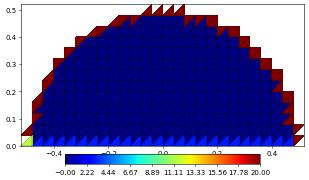

In [4]:
from dune.fem.utility import inspectBoundaryIds
inspectBoundaryIds(filteredView).plot(colorbar="horizontal")

Revert the filter and create a `filteredGridView` with also provides an overloaded index set
with a consecutive index for the entities belonging to the new domain.

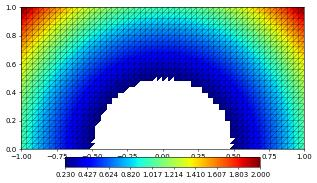

number of dofs: 4201 integral over filtered domain 1.2847470933333294


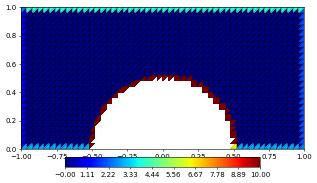

In [5]:
filteredView = filteredGridView(gridView, filterIds, domainId=20,
                                useFilteredIndexSet=True)
space = lagrange(filteredView, order=2)
x = SpatialCoordinate(space)
solution = space.interpolate(dot(x,x),name="solution")
solution.plot(colorbar="horizontal")
print("number of dofs:", solution.size,\
      "integral over filtered domain",solution.integrate())
inspectBoundaryIds(filteredView).plot(colorbar="horizontal")

Compare with the original grid view.

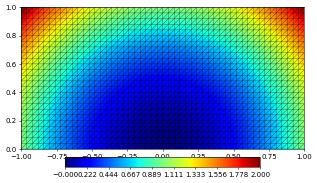

number of dofs: 5151 integral over filtered domain 1.3333333333333286


In [6]:
space = lagrange(gridView, order=2)
solution = space.interpolate(dot(x,x),name="solution")
solution.plot(colorbar="horizontal")
print("number of dofs:", solution.size,\
      "integral over filtered domain",solution.integrate())

Finally we solve a simple linear PDE but with some mixed boundary conditions taken
from one of the [introduction notebooks](concepts_nb.ipynb)

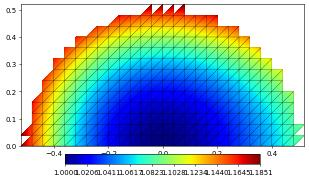

In [7]:
from dune.ufl import DirichletBC
from dune.fem.scheme import galerkin
from ufl import ( TrialFunction, TestFunction, FacetNormal, conditional,
                  div, grad, dx, ds )
filteredView = filteredGridView(gridView, filterIds, domainId=10)
space = lagrange(filteredView, order=2)
exact = 1/2*(x[0]**2+x[1]**2) - 1/3*(x[0]**3 - x[1]**3) + 1
u     = TrialFunction(space)
v     = TestFunction(space)
f     = -div( grad(exact) )
g_N   = grad(exact)
n     = FacetNormal(space)
b     = f*v*dx + dot(g_N,n)*conditional(x[0]>=1e-8,1,0)*v*ds
a     = dot(grad(u), grad(v)) * dx
dbc   = DirichletBC(space,exact,x[0]<=1e-8)

solution = space.interpolate(0,name="solution")
scheme = galerkin([a == b, dbc], solver='cg')
scheme.solve(target = solution)
solution.plot(colorbar="horizontal")

Let’s compare with the exact solution

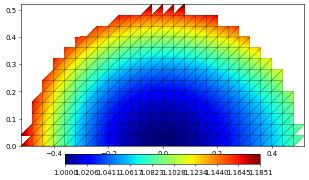

In [8]:
from dune.fem.function import gridFunction
gridFunction(exact,gridView=filteredView).plot(level=3,colorbar="horizontal")